# T29. Cobertura con recorridos a pie

**Pregunta.** ¿Cómo cambia la cobertura OD al medir acceso por calles y pasos transitables, manteniendo las estaciones de T28 y los radios?

Se usan dos núcleos fijados sobre barreras distintas, el Tíber a la altura de Trastevere y el corredor ferroviario de Termini. En cada núcleo entran los viajes con origen y destino dentro de su rectángulo. El grafo cubre un recorte mayor, con margen superior al radio máximo y al enlace de 60 m. Las vías y sus nodos provienen de la instantánea de OpenStreetMap archivada con su fecha y huella. La cartografía describe el momento de descarga, mientras que los viajes proceden de febrero de 2021.

,periodo,sector,viajes_sector,nodos,tramos,margen_min_m,extremos_sin_enlace,estaciones_sector,estaciones_sin_enlace
0,ajuste,tiber,634,74871,84387,1241.5,0,114,2
1,ajuste,termini,338,32826,37431,513.1,0,37,3


,network_id,sector,viajes_sector,viajes_comparables,viajes_sin_par_rutas,pct_linea,pct_a_pie,delta_pp,p90_linea_m,p90_a_pie_m,pierde_origen,pierde_destino,pierde_ambos,cambios_estacion
0,lscp_r250_k225,tiber,634,628,6,89.49,47.77,-41.72,227.15,338.13,98,115,49,34
1,lscp_r300_k159,tiber,634,628,6,87.26,48.41,-38.85,273.83,401.65,91,102,51,60
2,mclp_r300_k158,tiber,634,628,6,87.26,48.41,-38.85,273.83,401.65,91,102,51,60
3,lscp_r250_k225,termini,338,338,0,79.29,47.93,-31.36,285.78,406.95,47,41,18,23
4,lscp_r300_k159,termini,338,338,0,83.43,36.98,-46.45,295.91,433.76,57,70,30,32
5,mclp_r300_k158,termini,338,338,0,83.43,36.98,-46.45,295.91,433.76,57,70,30,32
6,lscp_r250_k225,ambos,972,966,6,85.92,47.83,-38.10,233.10,372.20,145,156,67,57
7,lscp_r300_k159,ambos,972,966,6,85.92,44.41,-41.51,285.74,413.05,148,172,81,92
8,mclp_r300_k158,ambos,972,966,6,85.92,44.41,-41.51,285.74,413.05,148,172,81,92


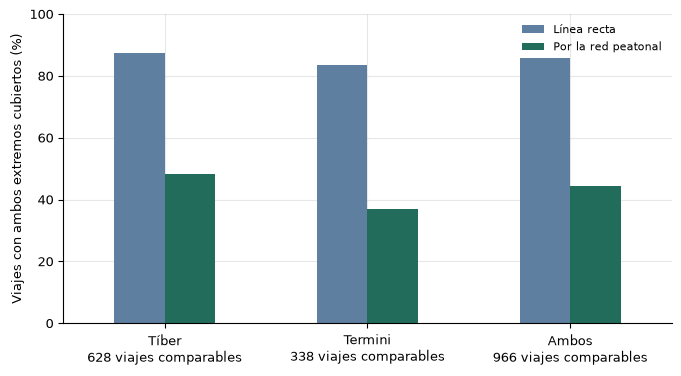

In [1]:
import hashlib
import json
from IPython.display import display

from comun.figuras import guardar_figura, plt
from peatones import evaluar, finalistas
from redes import TABLAS, guardar

redes, estaciones = finalistas()
tabla, control, ejemplos, curva = evaluar("ajuste", redes, estaciones)
guardar(tabla, "T29_cobertura_peatonal")
guardar(control, "T29_grafo")
guardar(curva, "T29_sensibilidad_radio")
fijada = {
    nombre: hashlib.sha256((TABLAS / nombre).read_bytes()).hexdigest()
    for nombre in ("T28_finalistas.csv", "T28_estaciones.csv")
}
(TABLAS / "T29_rutas_ajuste.json").write_text(
    json.dumps({"seleccion": fijada, "ejemplos": ejemplos}, ensure_ascii=False, separators=(",", ":")) + "\n",
    encoding="utf-8", newline="\n")
display(control.round(1))
display(tabla[["network_id", "sector", "viajes_sector", "viajes_comparables", "viajes_sin_par_rutas",
               "pct_linea", "pct_a_pie", "delta_pp", "p90_linea_m", "p90_a_pie_m",
               "pierde_origen", "pierde_destino", "pierde_ambos", "cambios_estacion"]].round(2))

seleccionada = redes.loc[redes["rol"].eq("recomendada"), "network_id"].iloc[0]
r = tabla.loc[tabla["network_id"].eq(seleccionada)].set_index("sector").loc[["tiber", "termini", "ambos"]]
fig, eje = plt.subplots(figsize=(6.7, 3.65), layout="constrained")
r[["pct_linea", "pct_a_pie"]].reset_index(drop=True).plot.bar(
    color=["#5e7f9f", "#226c5b"], ax=eje, rot=0)
eje.set_xticklabels([f"{nombre}\n{n} viajes comparables" for nombre, n in
                    zip(["Tíber", "Termini", "Ambos"], r["viajes_comparables"])])
eje.set(ylabel="Viajes con ambos extremos cubiertos (%)", xlabel="", ylim=(0, 100), axisbelow=True)
eje.legend(["Línea recta", "Por la red peatonal"], frameon=False, loc="upper right")
guardar_figura(fig, "movilidad", "T29_cobertura_peatonal")

**Lectura.** El punto observado y la estación se proyectan sobre un tramo transitable cercano. Se suma la distancia de sus enlaces y la del camino más corto por calles. Los conectores no pueden atajar sobre los ejes de río o ferrocarril. Se respetan los sentidos peatonales y las restricciones explícitas del grafo.

Los porcentajes y los P90 se calculan sobre los mismos viajes con ruta finita en los dos extremos. La tabla publica por separado los viajes sin par de rutas y el recuento total verificado. Un cambio de estación se cuenta si las dos distancias del extremo están en radio y las estaciones elegidas son distintas. Los resultados corresponden a los dos núcleos estudiados.

**Pérdidas y sensibilidad.** Entre los viajes que sí cumplen en recta y tienen las dos rutas medibles, se cuenta si el umbral se rebasa en el origen, en el destino o en ambos. La suma de las tres pérdidas más los viajes que se mantienen cubiertos coincide con la cobertura en recta del grupo comparable. Para medir la sensibilidad al umbral se evalúan 200, 250, 300, 350 y 400 m, con las mismas estaciones y los mismos viajes comparables en cada punto de la curva.